# Landsat 8/9: quality flags and CAMS auxiliary data

The GRS atmospheric correction needs the state of the atmosphere at the time of the image:
surface pressure, ozone, water vapour, aerosols and wind. They are taken from the Copernicus
Atmosphere Monitoring Service (CAMS). This tutorial loads a full Landsat 9 scene with its quality
flags, and colocates the CAMS global forecasts with it.

**You will learn to**

- load a full Landsat scene and decode its quality bitmask (`flags_l1`),
- open a CAMS file lazily and select the date of the image,
- subset, regrid and reproject the CAMS fields onto the image.

**Data**

- the Landsat 9 product of path/row 196/030 of 2022-11-20 (see the
  [thermal tutorial](GRSdriver_landsat9_TIR.ipynb)),
- the CAMS global atmospheric composition forecasts of November 2022 (3-hourly, 0.4°), downloaded
  from the [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) as a single netCDF file.

In [1]:
import numpy as np
import xarray as xr
import rioxarray  # noqa: F401 (rio accessor)
import matplotlib.pyplot as plt
import matplotlib as mpl
import cartopy.crs as ccrs

import GRSdriver
from GRSdriver import LandsatDriver

print('GRSdriver', GRSdriver.__version__)

GRSdriver 2.0.0


In [2]:
def utm_projection(crs):
    """Cartopy UTM projection of a product CRS (EPSG 326xx: north, 327xx: south)."""
    epsg = crs.to_epsg()
    return ccrs.UTM(epsg % 100, southern_hemisphere=epsg // 100 == 327)

In [3]:
image = '/data/satellite/landsat/LC09_L1TP_196030_20221120_20230321_02_T1'
cams_file = '/data/cams/world/cams_forecast_2022-11.nc'

## Load the full scene

A coarse resolution (90 m) keeps the tutorial light; the bitmask is resampled with nearest
neighbour and the bands are averaged:

In [4]:
%%time
l1 = LandsatDriver(image, band_idx=[1, 2, 4, 5, 9], resolution=90)   # BLUE, GREEN, RED, NIR, TIR_1
l1.load_product()
prod = l1.prod
proj = utm_projection(prod.rio.crs)
prod

CPU times: user 17 s, sys: 3.09 s, total: 20.1 s
Wall time: 20.1 s


<xarray.Dataset> Size: 319MB
Dimensions:      (x: 2557, y: 2597, wl: 5, wl_hr: 2951)
Coordinates:
  * x            (x) float64 20kB 5.349e+05 5.35e+05 ... 7.649e+05 7.65e+05
  * y            (y) float64 21kB 4.899e+06 4.899e+06 ... 4.666e+06 4.666e+06
  * wl           (wl) float64 40B 490.0 560.0 665.0 865.0 1.1e+04
  * wl_hr        (wl_hr) float64 24kB 400.0 401.0 402.0 ... 1.35e+04 1.35e+04
    spatial_ref  int64 8B 0
    time         datetime64[ns] 8B 2022-11-20T10:24:21
Data variables:
    bands        (wl, y, x) float32 133MB nan nan nan nan ... nan nan nan nan
    SRF          (wl, wl_hr) float64 118kB ...
    wl_true      (wl) float64 40B 482.3 560.9 654.3 864.6 1.084e+04
    sza          (y, x) float64 53MB nan nan nan nan nan ... nan nan nan nan nan
    vza          (y, x) float64 53MB nan nan nan nan nan ... nan nan nan nan nan
    raa          (y, x) float64 53MB nan nan nan nan nan ... nan nan nan nan nan
    flags_l1     (y, x) uint32 27MB 1 1 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1 1 1 1
Attributes: (12/16)
    long_name:              BLUE GREEN RED NIR TIR_1
    constellation:          Landsat-9
    constellation_id:       L9
    product_path:           /data/satellite/landsat/LC09_L1TP_196030_20221120...
    product_name:           LC09_L1TP_196030_20221120_20230321_02_T1
    instrument:             OLI-TIRS
    ...                     ...
    radiometry:             reflectance and brightness temperature
    cloud_cover:            0.2
    wl_to_process:          [ 443  490  560  590  665  865 1610 2190]
    satellite:              Landsat-9
    solar_irradiance:       NA
    solar_irradiance_unit:  W/m²/µm

## Quality flags

`flags_l1` is the `QA_PIXEL` bitmask of the Collection 2 products. Each bit is a flag; the main ones:

| bit | flag |
|---|---|
| 0 | fill (no data) |
| 1 | dilated cloud |
| 2 | cirrus |
| 3 | cloud |
| 4 | cloud shadow |
| 5 | snow |
| 6 | clear |
| 7 | water |

A flag is extracted with a bitwise AND. The fill pixels (value 1, outside the scene) are
excluded from the statistics:

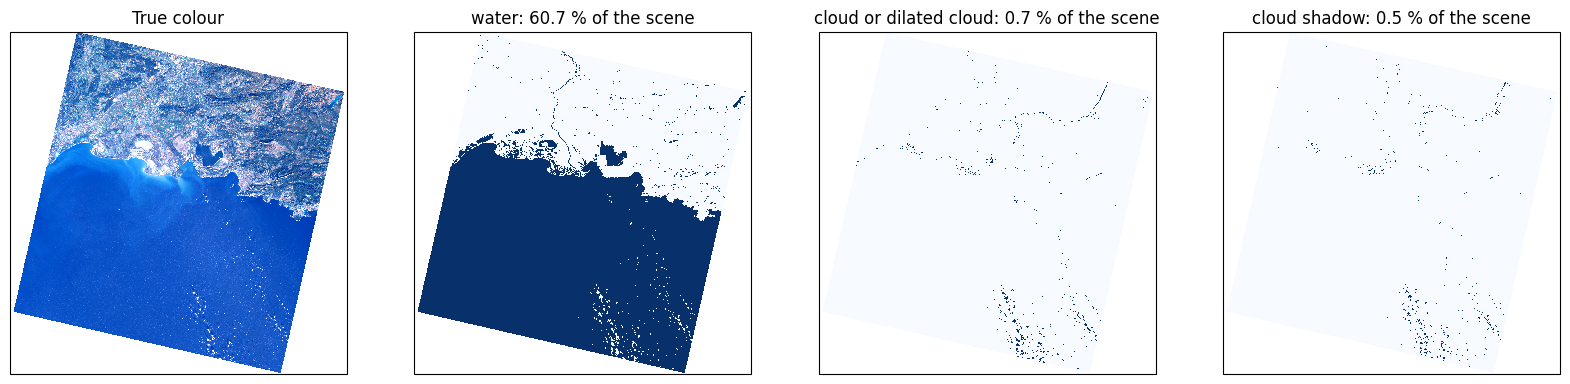

In [5]:
def flag(flags, bit):
    """True where the bit is set."""
    return (flags & (1 << bit)) > 0

masks = {'water': flag(prod.flags_l1, 7),
         'cloud or dilated cloud': flag(prod.flags_l1, 3) | flag(prod.flags_l1, 1),
         'cloud shadow': flag(prod.flags_l1, 4)}

valid = ~flag(prod.flags_l1, 0)

fig, axs = plt.subplots(1, 4, figsize=(20, 5.5), subplot_kw={'projection': proj})
(prod.bands.sel(wl=[665, 560, 490]) ** 0.5).plot.imshow(ax=axs[0], rgb='wl', robust=True, transform=proj)
axs[0].set_title('True colour')
for ax, (name, mask) in zip(axs[1:], masks.items()):
    mask = mask.where(valid)
    mask.plot.imshow(ax=ax, transform=proj, cmap='Blues', add_colorbar=False)
    ax.set_title(f'{name}: {float(mask.mean()) * 100:.1f} % of the scene')
plt.show()

## CAMS forecasts

The file covers the globe for a whole month. Opened lazily, only the selected data are read:

In [6]:
cams = xr.open_dataset(cams_file)
cams

<xarray.Dataset> Size: 17GB
Dimensions:    (time: 240, latitude: 451, longitude: 900)
Coordinates:
  * time       (time) datetime64[ns] 2kB 2022-11-01 ... 2022-11-30T21:00:00
  * latitude   (latitude) float32 2kB 90.0 89.6 89.2 88.8 ... -89.2 -89.6 -90.0
  * longitude  (longitude) float32 4kB -180.0 -179.6 -179.2 ... 179.2 179.6
Data variables: (12/22)
    v10        (time, latitude, longitude) float64 779MB ...
    t2m        (time, latitude, longitude) float64 779MB ...
    msl        (time, latitude, longitude) float64 779MB ...
    sp         (time, latitude, longitude) float64 779MB ...
    amaod550   (time, latitude, longitude) float64 779MB ...
    bcaod550   (time, latitude, longitude) float64 779MB ...
    ...         ...
    tcco       (time, latitude, longitude) float64 779MB ...
    tc_ch4     (time, latitude, longitude) float64 779MB ...
    tcno2      (time, latitude, longitude) float64 779MB ...
    gtco3      (time, latitude, longitude) float64 779MB ...
    tcwv       (time, latitude, longitude) float64 779MB ...
    u10        (time, latitude, longitude) float64 779MB ...
Attributes:
    Conventions:  CF-1.6
    history:      2024-02-21 18:34:02 GMT by grib_to_netcdf-2.25.1: /opt/ecmw...

Keep the forecasts of the day of the image, and declare the geographic CRS of the grid:

In [7]:
date = prod.time.dt.strftime('%Y-%m-%d').item()
cams = cams.sel(time=date).rio.write_crs(4326)
cams.time.values

array(['2022-11-20T00:00:00.000000000', '2022-11-20T03:00:00.000000000',
       '2022-11-20T06:00:00.000000000', '2022-11-20T09:00:00.000000000',
       '2022-11-20T12:00:00.000000000', '2022-11-20T15:00:00.000000000',
       '2022-11-20T18:00:00.000000000', '2022-11-20T21:00:00.000000000'],
      dtype='datetime64[ns]')

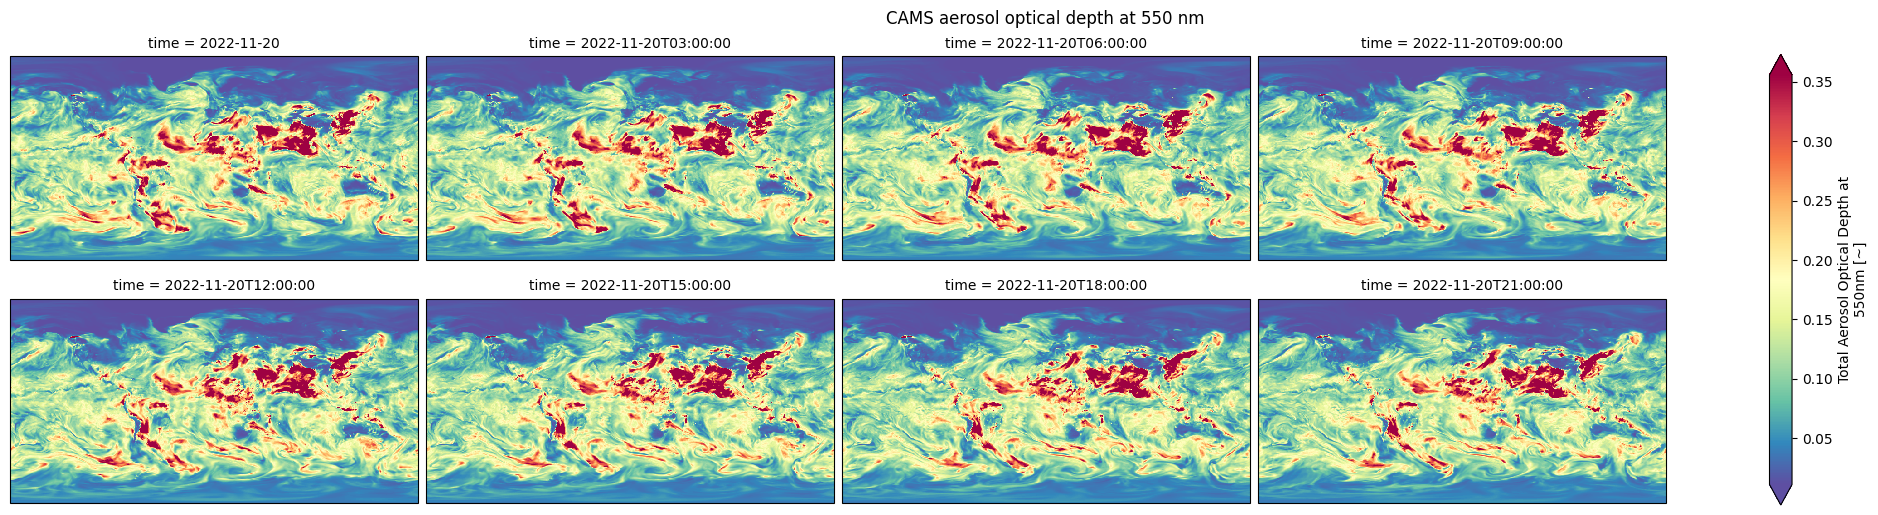

In [8]:
cams.aod550.plot.imshow(col='time', col_wrap=4, cmap='Spectral_r', robust=True, size=2.5, aspect=2,
                        subplot_kws={'projection': ccrs.PlateCarree()}, transform=ccrs.PlateCarree())
plt.suptitle('CAMS aerosol optical depth at 550 nm', y=1.02)
plt.show()

## Colocation with the image

1. Select a window around the image (1 deg margin). CAMS longitudes go from 0 to 360 deg: they are
   converted to -180 / 180 deg when the image crosses the Greenwich meridian.

In [9]:
lonmin, latmin, lonmax, latmax = prod.rio.transform_bounds(4326)

cams = cams.sel(latitude=slice(latmax + 1, latmin - 1))
if cams.longitude.min() >= 0:
    if lonmin <= 0 <= lonmax:
        cams = cams.assign_coords(longitude=((cams.longitude + 180) % 360) - 180).sortby('longitude')
    else:
        lonmin, lonmax = lonmin % 360, lonmax % 360
cams = cams.sel(longitude=slice(lonmin - 1, lonmax + 1))
dict(cams.sizes)

{'time': 8, 'latitude': 11, 'longitude': 12}

2. The image covers only a few CAMS cells: interpolate them on a finer grid, for smooth fields.
3. Reproject on the CRS of the image and clip to its extent.

In [10]:
n = 100
cams = cams.interp(latitude=np.linspace(float(cams.latitude.max()), float(cams.latitude.min()), n),
                   longitude=np.linspace(float(cams.longitude.min()), float(cams.longitude.max()), n))
cams = cams.rio.reproject(prod.rio.crs, nodata=np.nan).rio.clip_box(*prod.rio.bounds())
dict(cams.sizes)

{'x': 57, 'y': 59, 'time': 8}

Finally, take the forecast closest to the acquisition time:

In [11]:
cams_ = cams.sel(time=prod.time, method='nearest')
wind = np.sqrt(cams_.u10 ** 2 + cams_.v10 ** 2).rename('wind speed (m/s)')
print('image:', prod.time.values, '| CAMS:', cams_.time.values)

image: 2022-11-20T10:24:21.000000000 | CAMS: 2022-11-20T09:00:00.000000000


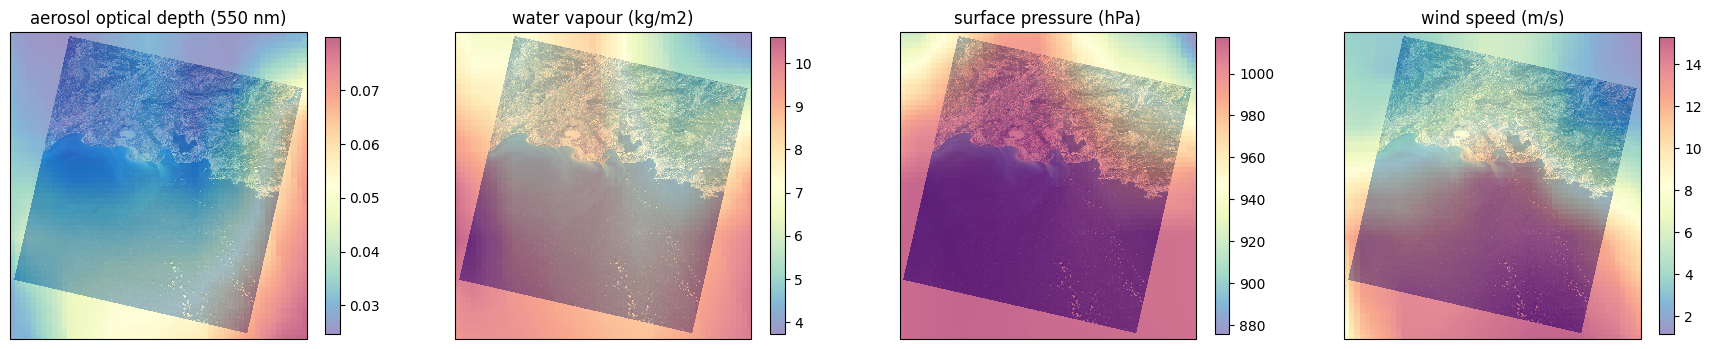

In [12]:
fields = {'aerosol optical depth (550 nm)': cams_.aod550,
          'water vapour (kg/m2)': cams_.tcwv,
          'surface pressure (hPa)': cams_.sp / 100,
          'wind speed (m/s)': wind}

fig, axs = plt.subplots(1, 4, figsize=(22, 5.5), subplot_kw={'projection': proj})
for ax, (name, field) in zip(axs, fields.items()):
    (prod.bands.sel(wl=[665, 560, 490]) ** 0.5).plot.imshow(ax=ax, rgb='wl', robust=True, transform=proj)
    field.plot.imshow(ax=ax, cmap='Spectral_r', alpha=0.6, transform=proj,
                      cbar_kwargs={'shrink': 0.7, 'label': ''})
    ax.set_title(name)
plt.show()

## Next steps

The GRS processor does this colocation for you (`cams_file` or a CAMS directory in its options):
this tutorial shows what happens under the hood, and how to check the auxiliary data of an image.